In [2]:
# Support Ticket Classification and Prioritization Using Machine Learning

## 1. Problem Statement
## 2. Dataset Overview
## 3. Data Cleaning and Feature Engineering
## 4. Exploratory Data Analysis
## 5. Ticket Category Classification
## 6. Ticket Priority Prediction
## 7. Model Evaluation
## 8. Business Impact and Conclusion

In [3]:
from pathlib import Path
import re
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 150)

possible_paths = [
    Path("customer_support_tickets (1).csv"),
    Path(r"C:\Users\ariva\Downloads\customer_support_tickets (1).csv")
]

csv_path = next((p for p in possible_paths if p.exists()), None)

if csv_path is None:
    raise FileNotFoundError("Move the CSV into this project folder, then run this cell again.")

df = pd.read_csv(csv_path)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (8469, 17)


,Ticket ID,Customer Name,Customer Email,Customer Age,Customer Gender,Product Purchased,Date of Purchase,Ticket Type,Ticket Subject,Ticket Description,Ticket Status,Resolution,Ticket Priority,Ticket Channel,First Response Time,Time to Resolution,Customer Satisfaction Rating
0,1,Marisa Obrien,carrollallison@example.com,32,Other,GoPro Hero,2021-03-22,Technical issue,Product setup,I'm having an issue with the {product_purchased}. Please assist.\n\nYour billing zip code is: 71701.\n\nWe appreciate that you have requested a we...,Pending Customer Response,NaN,Critical,Social media,2023-06-01 12:15:36,NaN,NaN
1,2,Jessica Rios,clarkeashley@example.com,42,Female,LG Smart TV,2021-05-22,Technical issue,Peripheral compatibility,I'm having an issue with the {product_purchased}. Please assist.\n\nIf you need to change an existing product.\n\nI'm having an issue with the {pr...,Pending Customer Response,NaN,Critical,Chat,2023-06-01 16:45:38,NaN,NaN
2,3,Christopher Robbins,gonzalestracy@example.com,48,Other,Dell XPS,2020-07-14,Technical issue,Network problem,"I'm facing a problem with my {product_purchased}. The {product_purchased} is not turning on. It was working fine until yesterday, but now it doesn...",Closed,Case maybe show recently my computer follow.,Low,Social media,2023-06-01 11:14:38,2023-06-01 18:05:38,3.0
3,4,Christina Dillon,bradleyolson@example.org,27,Female,Microsoft Office,2020-11-13,Billing inquiry,Account access,"I'm having an issue with the {product_purchased}. Please assist.\n\nIf you have a problem you're interested in and I'd love to see this happen, pl...",Closed,Try capital clearly never color toward story.,Low,Social media,2023-06-01 07:29:40,2023-06-01 01:57:40,3.0
4,5,Alexander Carroll,bradleymark@example.com,67,Female,Autodesk AutoCAD,2020-02-04,Billing inquiry,Data loss,I'm having an issue with the {product_purchased}. Please assist.\n\n\nNote: The seller is not responsible for any damages arising out of the deliv...,Closed,West decision evidence bit.,Low,Email,2023-06-01 00:12:42,2023-06-01 19:53:42,1.0


In [4]:
print("Missing values:")
display(df.isnull().sum().sort_values(ascending=False))

print("\nTicket Type distribution:")
display(df["Ticket Type"].value_counts())

print("\nOriginal Ticket Priority distribution:")
display(df["Ticket Priority"].value_counts())

Missing values:


Customer Satisfaction Rating    5700
Resolution                      5700
Time to Resolution              5700
First Response Time             2819
Ticket ID                          0
Customer Name                      0
Customer Email                     0
Customer Age                       0
Customer Gender                    0
Ticket Subject                     0
Ticket Type                        0
Date of Purchase                   0
Product Purchased                  0
Ticket Priority                    0
Ticket Status                      0
Ticket Description                 0
Ticket Channel                     0
dtype: int64


Ticket Type distribution:


Ticket Type
Refund request          1752
Technical issue         1747
Cancellation request    1695
Product inquiry         1641
Billing inquiry         1634
Name: count, dtype: int64


Original Ticket Priority distribution:


Ticket Priority
Medium      2192
Critical    2129
High        2085
Low         2063
Name: count, dtype: int64

In [5]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r"\{product_purchased\}", "product", text)
    text = re.sub(r"[^a-z\s]", " ", text)
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Use only information available when a ticket is created.
# Do NOT use status, resolution, response time, or satisfaction score:
# those fields can cause target leakage.
df["ticket_text"] = (
    df["Ticket Subject"].fillna("") + " " +
    df["Ticket Description"].fillna("") + " " +
    df["Product Purchased"].fillna("")
).apply(clean_text)

# Category target
df["category_target"] = df["Ticket Type"].fillna("Unknown").str.strip()

# The source has "Critical"; combine it with High to produce High/Medium/Low,
# as requested in the assignment.
df["priority_target"] = (
    df["Ticket Priority"]
    .fillna("Medium")
    .str.strip()
    .replace({"Critical": "High"})
)

model_df = df[["ticket_text", "category_target", "priority_target"]].dropna()
model_df = model_df[model_df["ticket_text"].str.len() > 0]

print("Usable rows:", len(model_df))
display(model_df.head())

Usable rows: 8469


,ticket_text,category_target,priority_target
0,product setup i m having an issue with the product please assist your billing zip code is we appreciate that you have requested a website address ...,Technical issue,High
1,peripheral compatibility i m having an issue with the product please assist if you need to change an existing product i m having an issue with the...,Technical issue,High
2,network problem i m facing a problem with my product the product is not turning on it was working fine until yesterday but now it doesn t respond ...,Technical issue,Low
3,account access i m having an issue with the product please assist if you have a problem you re interested in and i d love to see this happen pleas...,Billing inquiry,Low
4,data loss i m having an issue with the product please assist note the seller is not responsible for any damages arising out of the delivery of the...,Billing inquiry,Low


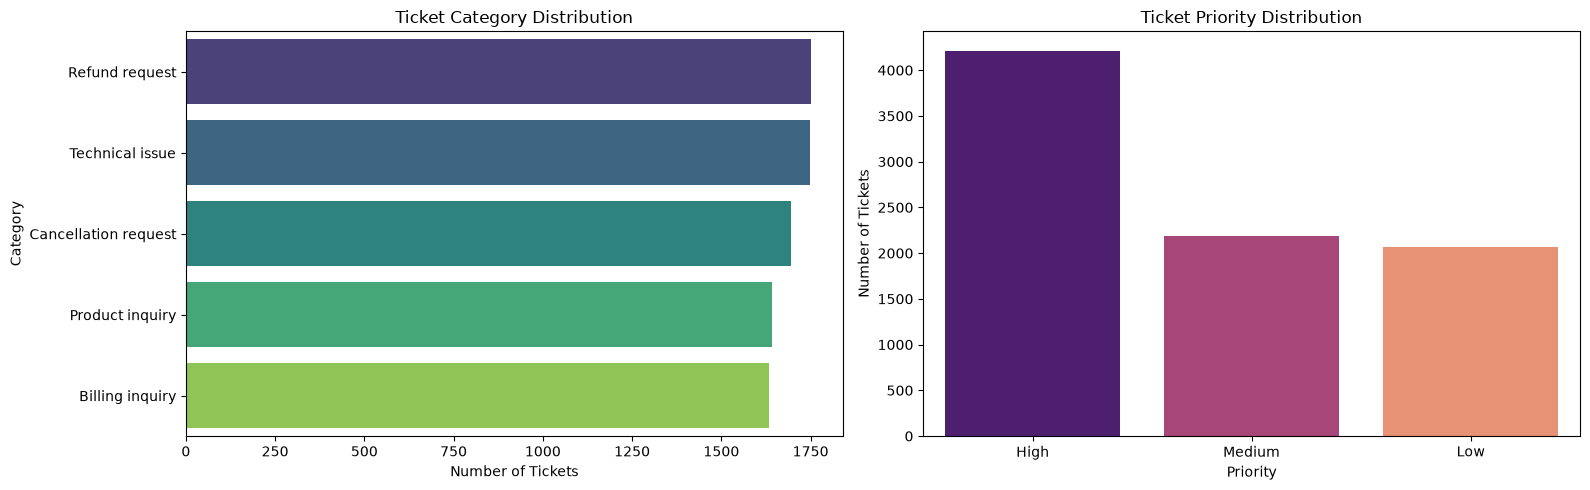

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

sns.countplot(
    data=model_df,
    y="category_target",
    order=model_df["category_target"].value_counts().index,
    ax=axes[0],
    palette="viridis"
)
axes[0].set_title("Ticket Category Distribution")
axes[0].set_xlabel("Number of Tickets")
axes[0].set_ylabel("Category")

sns.countplot(
    data=model_df,
    x="priority_target",
    order=["High", "Medium", "Low"],
    ax=axes[1],
    palette="magma"
)
axes[1].set_title("Ticket Priority Distribution")
axes[1].set_xlabel("Priority")
axes[1].set_ylabel("Number of Tickets")

plt.tight_layout()
plt.show()

In [7]:
X_category = model_df["ticket_text"]
y_category = model_df["category_target"]

X_train_cat, X_test_cat, y_train_cat, y_test_cat = train_test_split(
    X_category,
    y_category,
    test_size=0.20,
    random_state=42,
    stratify=y_category
)

category_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_features=15000
    )),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    ))
])

category_model.fit(X_train_cat, y_train_cat)

category_predictions = category_model.predict(X_test_cat)

print("Category Classification Accuracy:", round(accuracy_score(y_test_cat, category_predictions), 4))
print("\nClassification Report:\n")
print(classification_report(y_test_cat, category_predictions))

Category Classification Accuracy: 0.2107

Classification Report:

                      precision    recall  f1-score   support

     Billing inquiry       0.22      0.23      0.22       327
Cancellation request       0.21      0.21      0.21       339
     Product inquiry       0.20      0.22      0.21       328
      Refund request       0.20      0.19      0.20       351
     Technical issue       0.22      0.20      0.21       349

            accuracy                           0.21      1694
           macro avg       0.21      0.21      0.21      1694
        weighted avg       0.21      0.21      0.21      1694



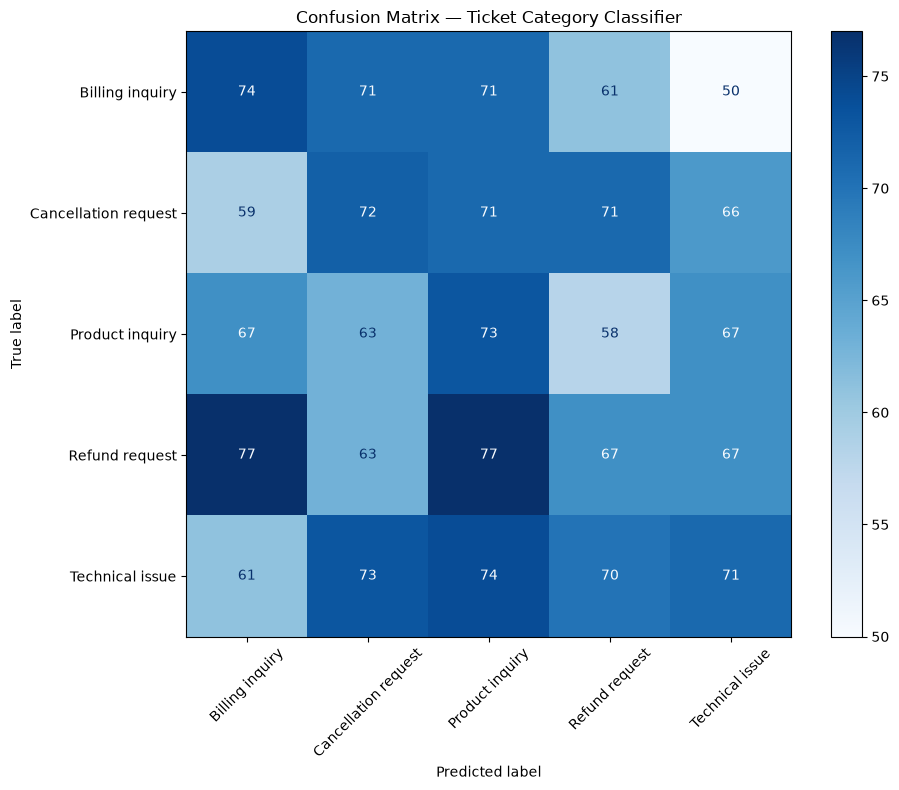

In [8]:
category_labels = sorted(y_category.unique())

fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay.from_predictions(
    y_test_cat,
    category_predictions,
    labels=category_labels,
    cmap="Blues",
    xticks_rotation=45,
    ax=ax
)
ax.set_title("Confusion Matrix — Ticket Category Classifier")
plt.tight_layout()
plt.show()

In [9]:
X_priority = model_df["ticket_text"]
y_priority = model_df["priority_target"]

X_train_pri, X_test_pri, y_train_pri, y_test_pri = train_test_split(
    X_priority,
    y_priority,
    test_size=0.20,
    random_state=42,
    stratify=y_priority
)

priority_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=2,
        max_features=15000
    )),
    ("classifier", LogisticRegression(
        max_iter=1500,
        class_weight="balanced",
        random_state=42
    ))
])

priority_model.fit(X_train_pri, y_train_pri)

priority_predictions = priority_model.predict(X_test_pri)

print("Priority Classification Accuracy:", round(accuracy_score(y_test_pri, priority_predictions), 4))
print("\nClassification Report:\n")
print(classification_report(y_test_pri, priority_predictions))

Priority Classification Accuracy: 0.3341

Classification Report:

              precision    recall  f1-score   support

        High       0.49      0.39      0.43       843
         Low       0.23      0.29      0.25       413
      Medium       0.24      0.28      0.26       438

    accuracy                           0.33      1694
   macro avg       0.32      0.32      0.31      1694
weighted avg       0.36      0.33      0.34      1694



In [10]:
def classify_ticket(subject, description, product=""):
    text = clean_text(f"{subject} {description} {product}")

    category = category_model.predict([text])[0]
    priority = priority_model.predict([text])[0]

    category_confidence = category_model.predict_proba([text]).max()
    priority_confidence = priority_model.predict_proba([text]).max()

    return {
        "Predicted Category": category,
        "Predicted Priority": priority,
        "Category Confidence": f"{category_confidence:.1%}",
        "Priority Confidence": f"{priority_confidence:.1%}"
    }

result = classify_ticket(
    subject="Unable to access my account",
    description="I cannot log in and I urgently need access to my account for work.",
    product="Microsoft Office"
)

result

{'Predicted Category': 'Refund request',
 'Predicted Priority': 'High',
 'Category Confidence': '25.6%',
 'Priority Confidence': '37.6%'}

In [11]:
print("""
Conclusion:
This project uses TF-IDF text features and Logistic Regression models to
automatically classify support-ticket categories and predict ticket priority.

Business value:
- Tickets can be routed to the correct support team faster.
- High-priority cases can be identified earlier.
- Manual sorting effort and customer response delays can be reduced.

Limitation:
Priority labels in the dataset may be noisy or unevenly distributed, so
priority predictions should assist human agents rather than fully replace them.
""")


Conclusion:
This project uses TF-IDF text features and Logistic Regression models to
automatically classify support-ticket categories and predict ticket priority.

Business value:
- Tickets can be routed to the correct support team faster.
- High-priority cases can be identified earlier.
- Manual sorting effort and customer response delays can be reduced.

Limitation:
Priority labels in the dataset may be noisy or unevenly distributed, so
priority predictions should assist human agents rather than fully replace them.



# Final Conclusion

This project developed a machine learning solution to classify customer-support tickets and predict their priority level. Ticket text was cleaned and converted into TF-IDF numerical features. Logistic Regression models were trained separately for ticket-category classification and priority prediction.

The models can provide an initial recommendation to support teams, helping them route tickets faster and identify potentially urgent cases. The evaluation results also show that generic or noisy ticket descriptions can make accurate classification challenging. In a real business setting, clearer ticket information, larger labelled datasets, and human review would improve the system’s reliability.